# 🛒 Online Shoppers Purchasing Intention — Classification Track (Part A + Part B)
**23CSE301 Machine Learning Capstone | Review 2**

---

## Objective
Predict whether an online shopping session will result in a **purchase (`Revenue = True`)** using all **10 classification algorithms** (Part A + Part B).

This notebook covers the complete pipeline across both reviews:

**Review 1 (Part A):**
1. Dataset loading & audit  
2. Exploratory Data Analysis (EDA)  
3. Data cleaning, feature engineering & preprocessing  
4. Training 5 Part-A classification models  
5. Evaluation (Accuracy, Weighted F1, Confusion Matrix)  
6. Preliminary comparison table  

**Review 2 (Part B):**

7. Training 5 Part-B classification models  
8. Full 10-model comparison table (Accuracy, Precision, Recall, F1, ROC-AUC)  
9. Final model selection with hyperparameter tuning  
10. Cross-validation on the best model  

**Dataset:** Online Shoppers Purchasing Intention (12,330 sessions, 18 features)  
**Target:** `Revenue` (binary: True/False)  
**`random_state = 42` used throughout for reproducibility.**

---
## 0 — Imports & Configuration

In [38]:
# Standard library
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn — preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Scikit-learn — Part A models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC

# Scikit-learn — Part B models (Review 2)
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

# Scikit-learn — metrics (all mandatory per Section 3.2)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    roc_curve, auc
)

# Scikit-learn — tuning & validation
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV,
    cross_val_score, StratifiedKFold
)
from sklearn.pipeline import Pipeline

# Plotting style
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
COLORS = sns.color_palette('Set2')

RANDOM_STATE = 42
print('All libraries imported successfully (Part A + Part B).')


All libraries imported successfully (Part A + Part B).


---
## 1 — Dataset Loading & Audit

We load the Online Shoppers dataset and perform a full audit:
shape, data types, missing-value counts, and the class distribution of `Revenue`.

In [39]:
# ------------------------------------------------------------------
# 1.1  Load dataset
# ------------------------------------------------------------------
import os
DATA_PATH = "online_shoppers_intention.csv" 
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")


Dataset loaded: 12330 rows x 18 columns


In [40]:
# ------------------------------------------------------------------
# 1.2  Shape, dtypes, first few rows
# ------------------------------------------------------------------
print('=== SHAPE ===')
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]}')
print()
print('=== DATA TYPES ===')
print(df.dtypes)
print()
print('=== TYPE SUMMARY ===')
print(df.dtypes.value_counts())
print()
print('=== FIRST 5 ROWS ===')
df.head()

=== SHAPE ===
Rows: 12,330   Columns: 18

=== DATA TYPES ===
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

=== TYPE SUMMARY ===
int64      7
float64    7
str        2
bool       2
Name: count, dtype: int64

=== FIRST 5 ROWS ===


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [41]:
# ------------------------------------------------------------------
# 1.3  Missing value audit
# ------------------------------------------------------------------
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print('Missing value audit:')
print(missing_df[missing_df['Missing Count'] > 0])
print(f'\nTotal missing values: {missing.sum()}')
if missing.sum() == 0:
    print('✔ No missing values found — dataset is complete.')

Missing value audit:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Total missing values: 0
✔ No missing values found — dataset is complete.


=== Revenue (Target) Distribution ===
         Count  Percentage
Revenue                   
False    10422       84.53
True      1908       15.47


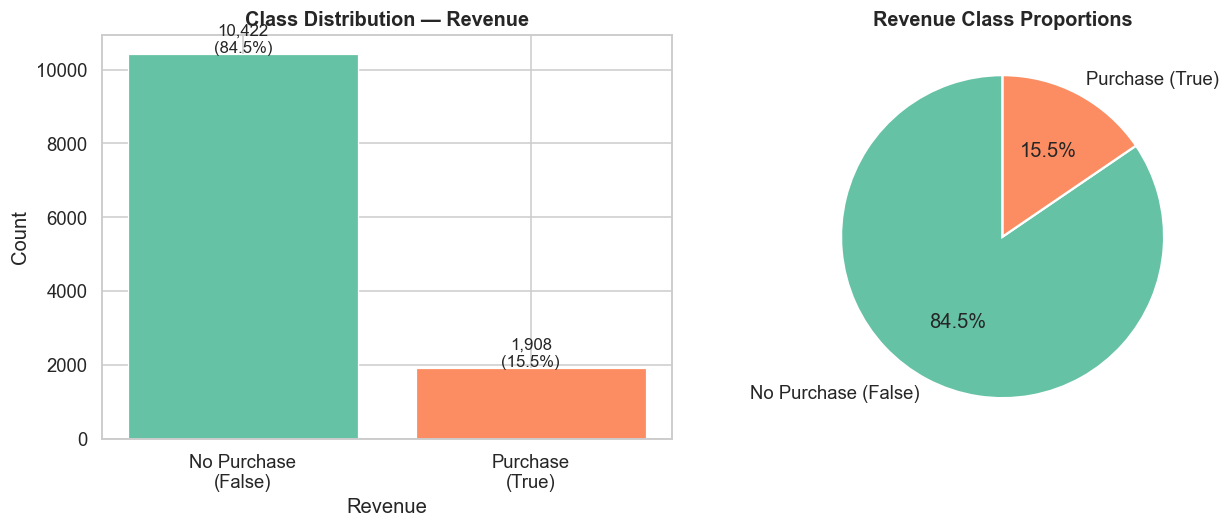

In [42]:
# ------------------------------------------------------------------
# 1.4  Class (target) distribution
# ------------------------------------------------------------------
print('=== Revenue (Target) Distribution ===')
vc = df['Revenue'].value_counts()
vc_pct = df['Revenue'].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': vc, 'Percentage': vc_pct.round(2)})
print(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(['No Purchase\n(False)', 'Purchase\n(True)'],
            [vc[False], vc[True]],
            color=[COLORS[0], COLORS[1]], edgecolor='white', linewidth=0.8)
axes[0].set_title('Class Distribution — Revenue', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Revenue')
for i, v in enumerate([vc[False], vc[True]]):
    axes[0].text(i, v + 50, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

# Pie chart
axes[1].pie([vc[False], vc[True]],
            labels=['No Purchase (False)', 'Purchase (True)'],
            colors=[COLORS[0], COLORS[1]],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Revenue Class Proportions', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**📝 Observation (Class Distribution):**  
- The dataset is **significantly imbalanced**: ~84.5% non-purchase sessions vs ~15.5% purchase sessions.  
- This means a naïve classifier that always predicts 'No Purchase' would achieve 84.5% accuracy — making **accuracy alone a misleading metric**.  
- Weighted F1-score is therefore more informative for evaluating classifier performance.  
- **Stratified train/test split** is essential to preserve this class ratio in both subsets.

---
## 2 — Exploratory Data Analysis (EDA)

Comprehensive EDA covering all 18 features with:
- Distribution plots for every feature
- Correlation heatmap
- Feature-target relationship plots

In [43]:
# ------------------------------------------------------------------
# 2.1  Identify feature types
# ------------------------------------------------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()

# Remove target from lists
if 'Revenue' in num_cols:  num_cols.remove('Revenue')
if 'Revenue' in cat_cols:  cat_cols.remove('Revenue')

print(f'Numerical features : {len(num_cols)} → {num_cols}')
print(f'Categorical/Bool features: {len(cat_cols)} → {cat_cols}')

Numerical features : 14 → ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical/Bool features: 3 → ['Month', 'VisitorType', 'Weekend']


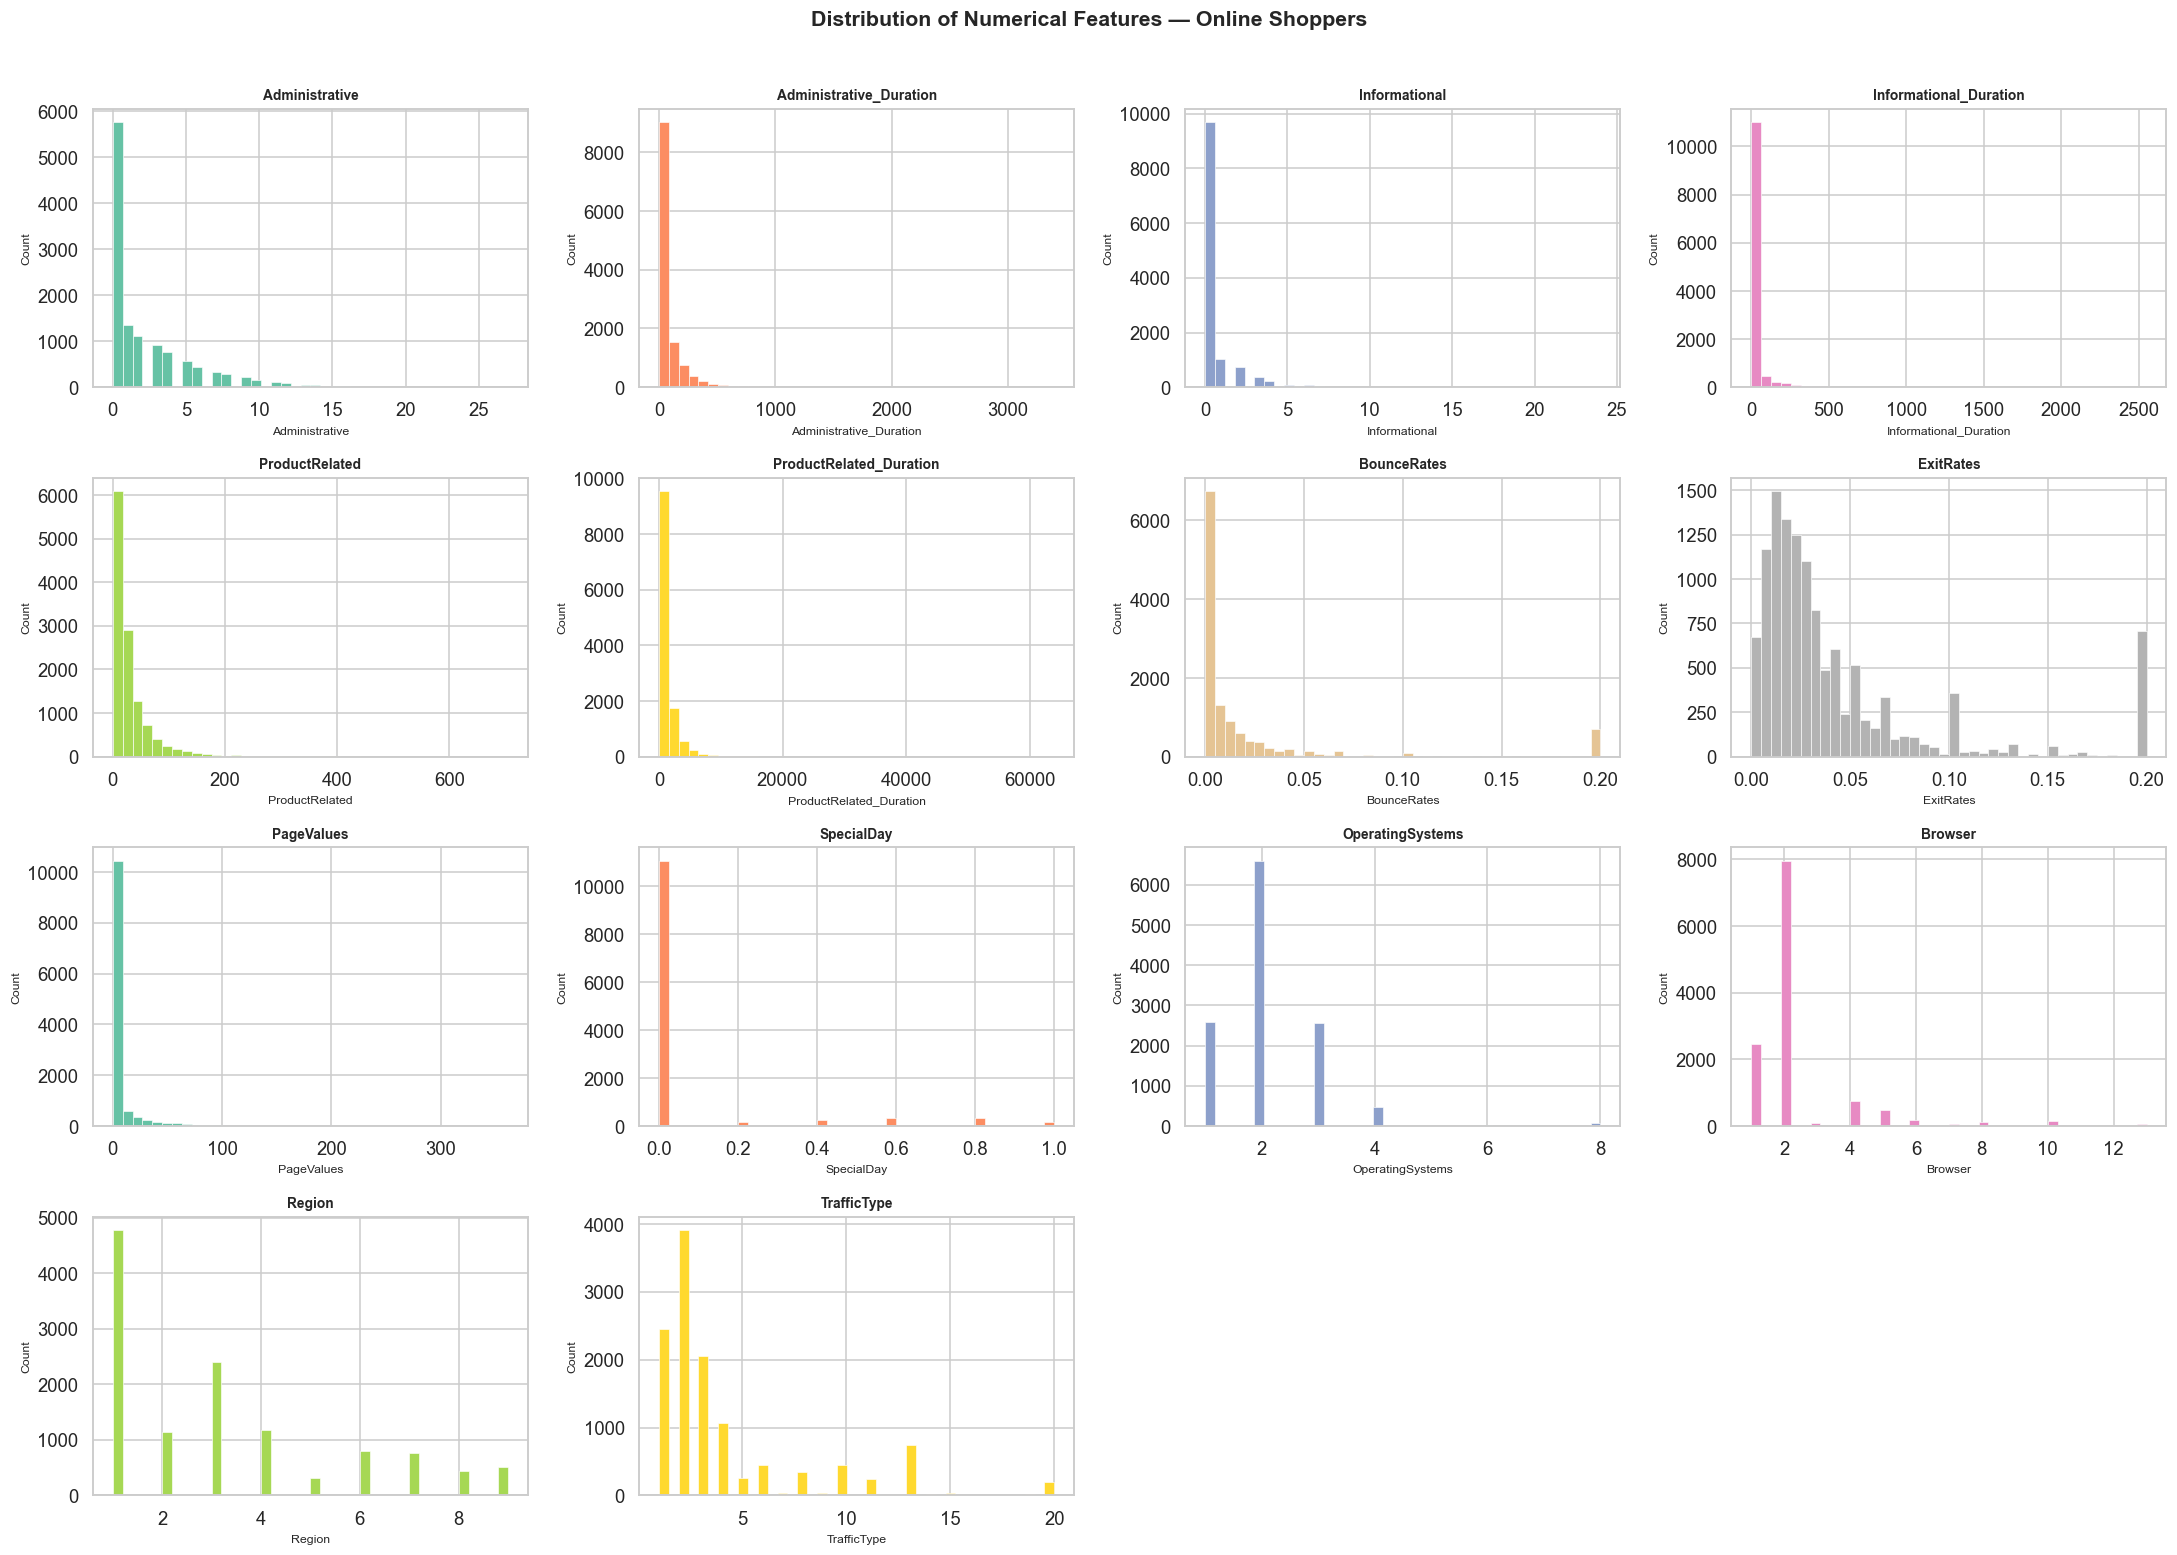

In [44]:
# ------------------------------------------------------------------
# 2.2  Distribution plots — Numerical features
# ------------------------------------------------------------------
n_num = len(num_cols)
ncols = 4
nrows = (n_num + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.5))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=40,
                 color=COLORS[i % len(COLORS)], edgecolor='white', linewidth=0.4)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribution of Numerical Features — Online Shoppers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**📝 Observation (Numerical Distributions):**  
- `Administrative`, `Informational`, and `ProductRelated` page counts are **heavily right-skewed** — most sessions visit very few pages, with a long tail of highly engaged visitors.  
- `BounceRates` and `ExitRates` are skewed toward zero — most visitors don't bounce immediately, indicating engagement.  
- `PageValues` is nearly zero for most sessions but has a long tail — high `PageValues` likely strongly predicts a purchase.  
- `SpecialDay` is mostly 0, indicating most visits don't occur near special commercial days.

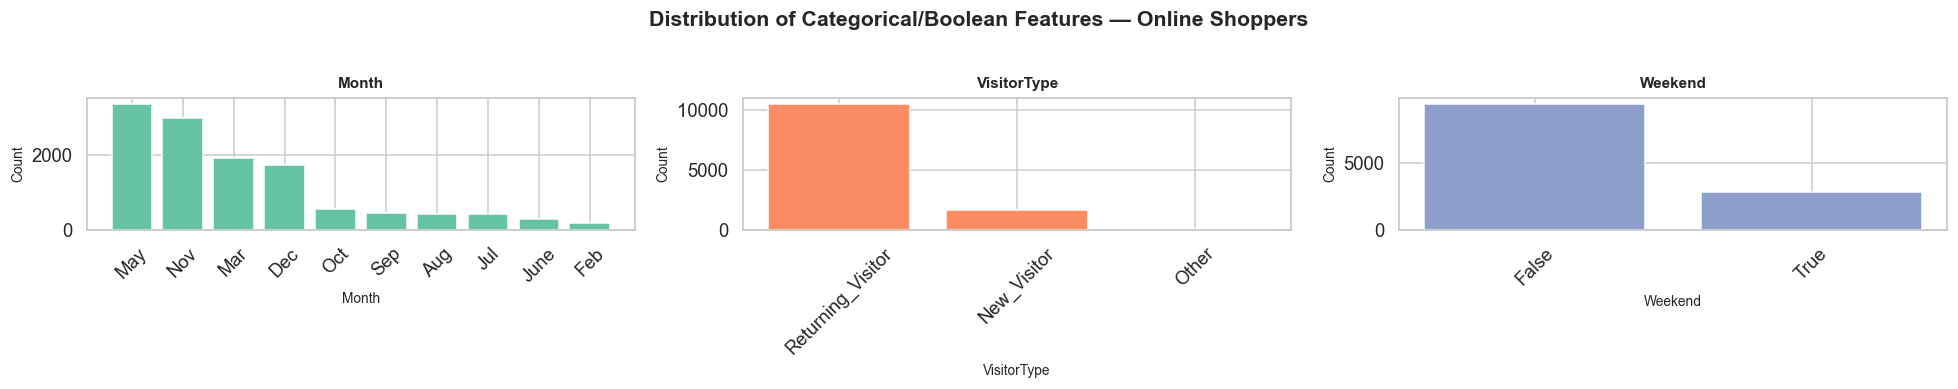

In [45]:
# ------------------------------------------------------------------
# 2.3  Distribution plots — Categorical / Boolean features
# ------------------------------------------------------------------
n_cat = len(cat_cols)
ncols_c = 3
nrows_c = (n_cat + ncols_c - 1) // ncols_c

fig, axes = plt.subplots(nrows_c, ncols_c, figsize=(18, nrows_c * 3.5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    vc = df[col].value_counts()
    axes[i].bar(vc.index.astype(str), vc.values,
                color=COLORS[i % len(COLORS)], edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel('Count', fontsize=9)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribution of Categorical/Boolean Features — Online Shoppers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**📝 Observation (Categorical Distributions):**  
- `Month` shows a non-uniform distribution — `May`, `November`, and `March` have the highest session counts.  
  November likely corresponds to Black Friday/Cyber Monday seasonal peaks.  
- `VisitorType` is dominated by `Returning_Visitor` (~85%), suggesting the majority of shoppers are repeat visitors.  
- `Weekend` is a binary flag where weekdays (~77%) outnumber weekends, reflecting typical browsing patterns.  
- `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are nominal integer codes that should be treated as categorical.

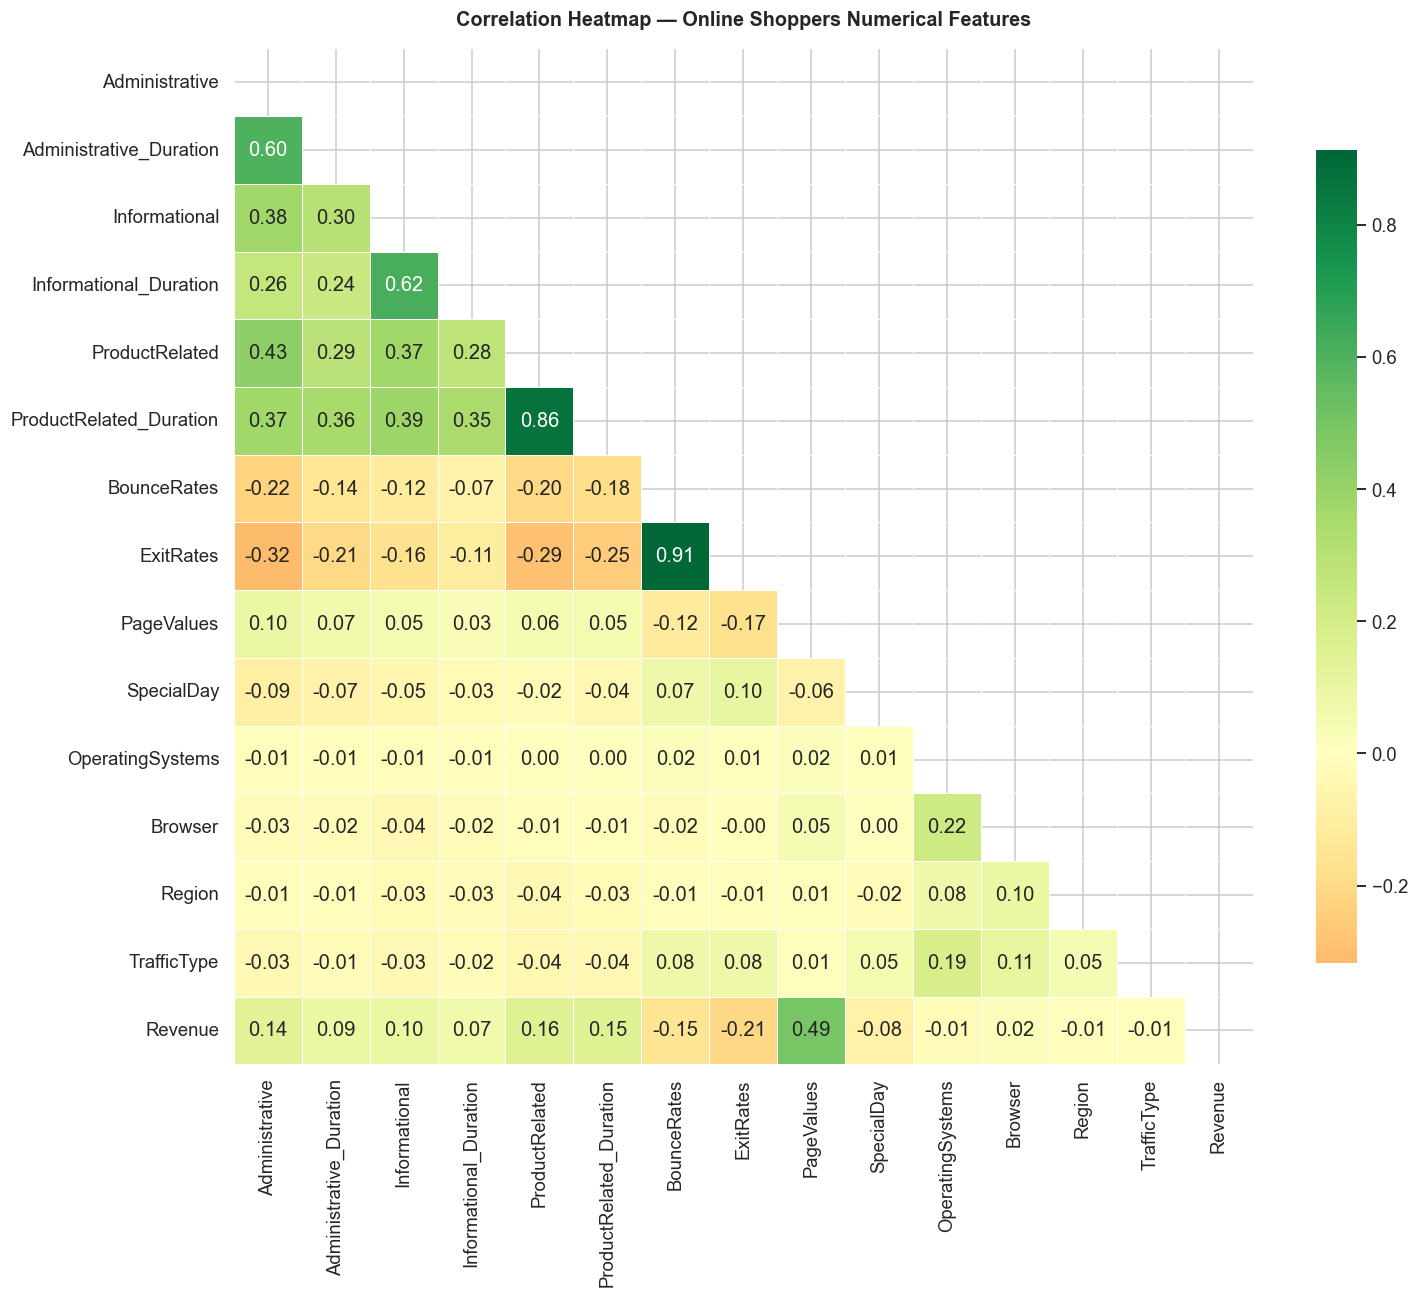

In [46]:
# ------------------------------------------------------------------
# 2.4  Correlation heatmap — Numerical features
# ------------------------------------------------------------------
df_corr = df[num_cols].copy()
# Add Revenue as 0/1 for correlation
df_corr['Revenue'] = df['Revenue'].astype(int)

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f', linewidths=0.5,
    cmap='RdYlGn', center=0,
    ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Correlation Heatmap — Online Shoppers Numerical Features',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**📝 Observation (Correlation Heatmap):**  
- `PageValues` has the **highest positive correlation with Revenue** (~0.49) — pages with high commercial value are strongly associated with completed purchases.  
- `BounceRates` and `ExitRates` are **highly correlated with each other** (~0.91), indicating near multicollinearity — using both may not add much information.  
- `ProductRelated` and `ProductRelated_Duration` are also highly correlated (~0.86), as expected.  
- Most numerical features have weak-to-moderate correlations with `Revenue`, suggesting non-linear models may perform better.

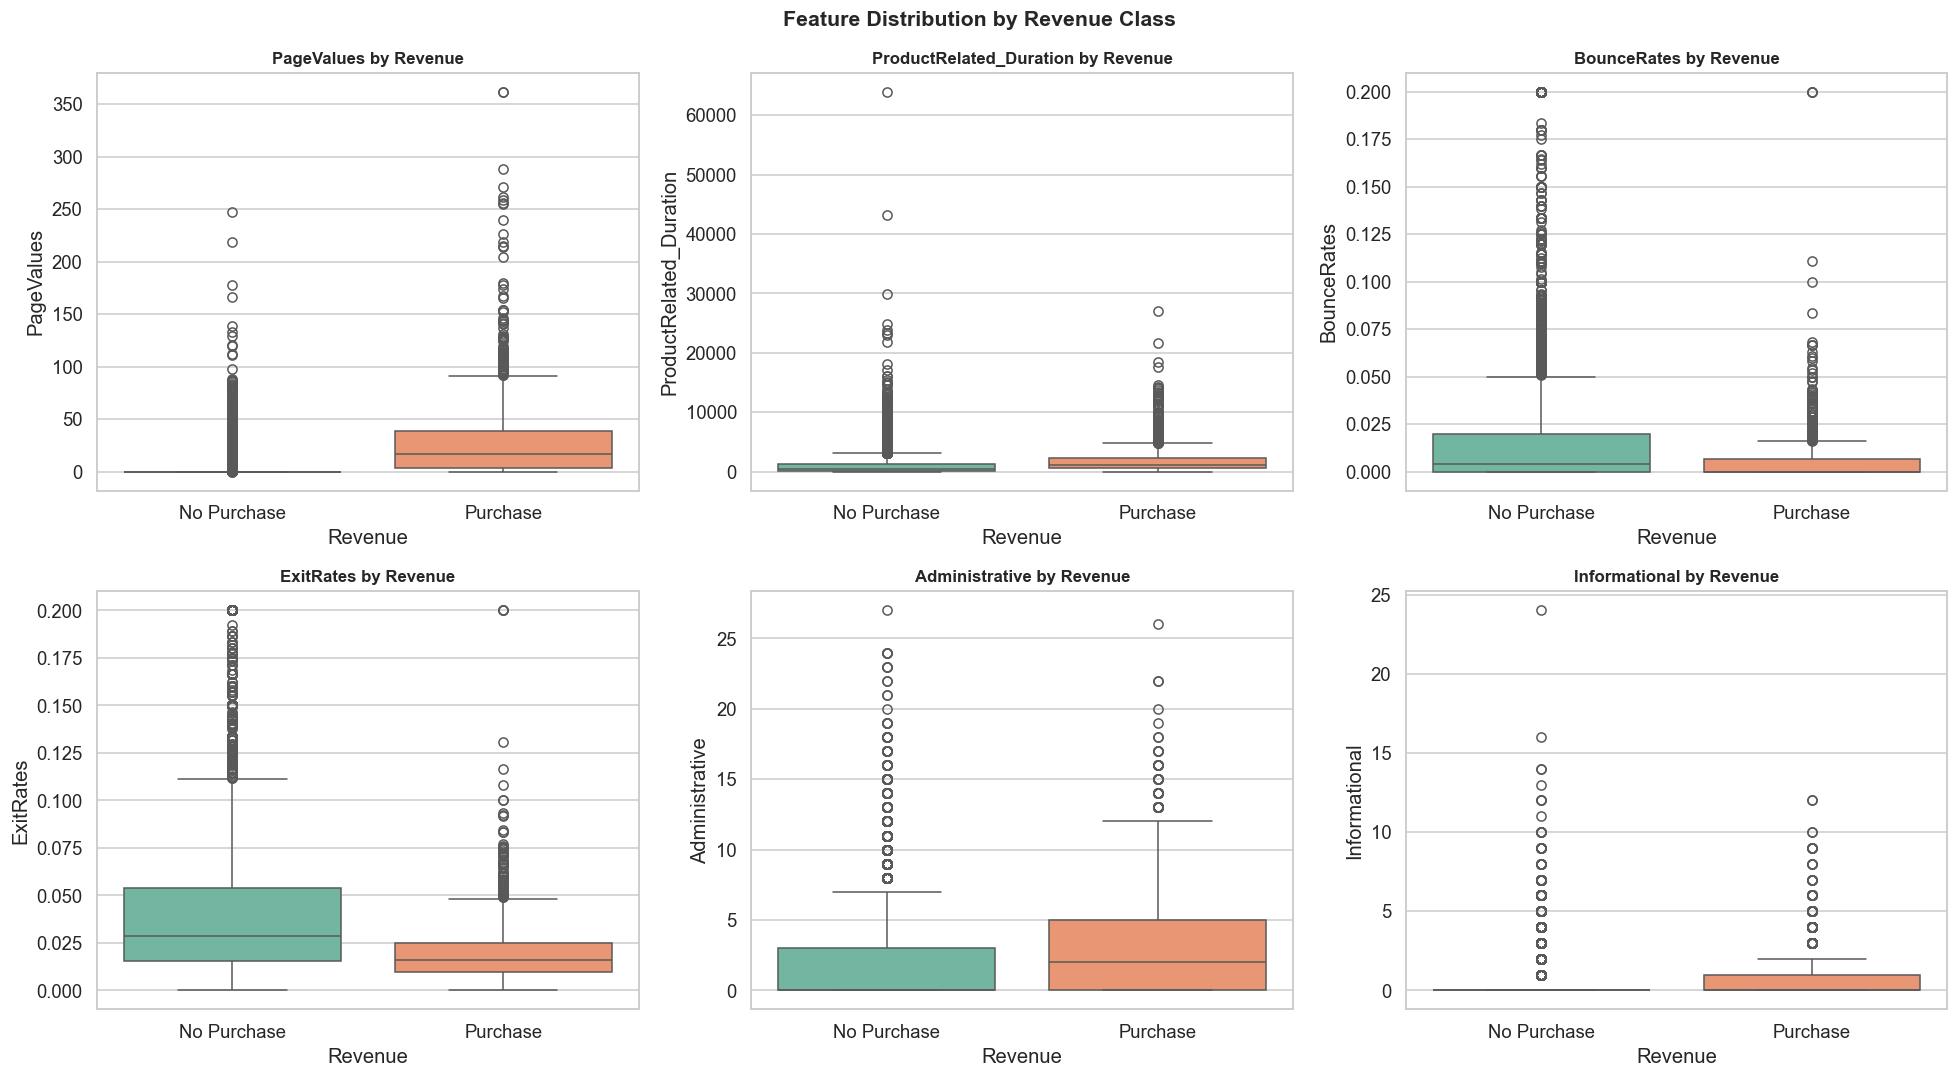

In [47]:
# ------------------------------------------------------------------
# 2.5  Feature-target relationship plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

key_features = ['PageValues', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates',
                'Administrative', 'Informational']

for i, feat in enumerate(key_features):
    df_plot = df[[feat, 'Revenue']].copy()
    df_plot['Revenue_Label'] = df_plot['Revenue'].map({False: 'No Purchase', True: 'Purchase'})
    sns.boxplot(data=df_plot, x='Revenue_Label', y=feat,
                palette='Set2', ax=axes[i])
    axes[i].set_title(f'{feat} by Revenue', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Revenue')
    axes[i].set_ylabel(feat)

fig.suptitle('Feature Distribution by Revenue Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**📝 Observation (Feature-Target Boxplots):**  
- `PageValues` shows the **most striking separation** between purchasers and non-purchasers — purchase sessions have a much higher median page value.  
- `ProductRelated_Duration` is also notably higher for purchasers — spending more time on product pages signals purchase intent.  
- `BounceRates` and `ExitRates` are slightly lower for purchasers, as expected — engaged visitors don't leave quickly.  
- These feature-target relationships confirm that `PageValues` will likely be the most important feature across classifiers.

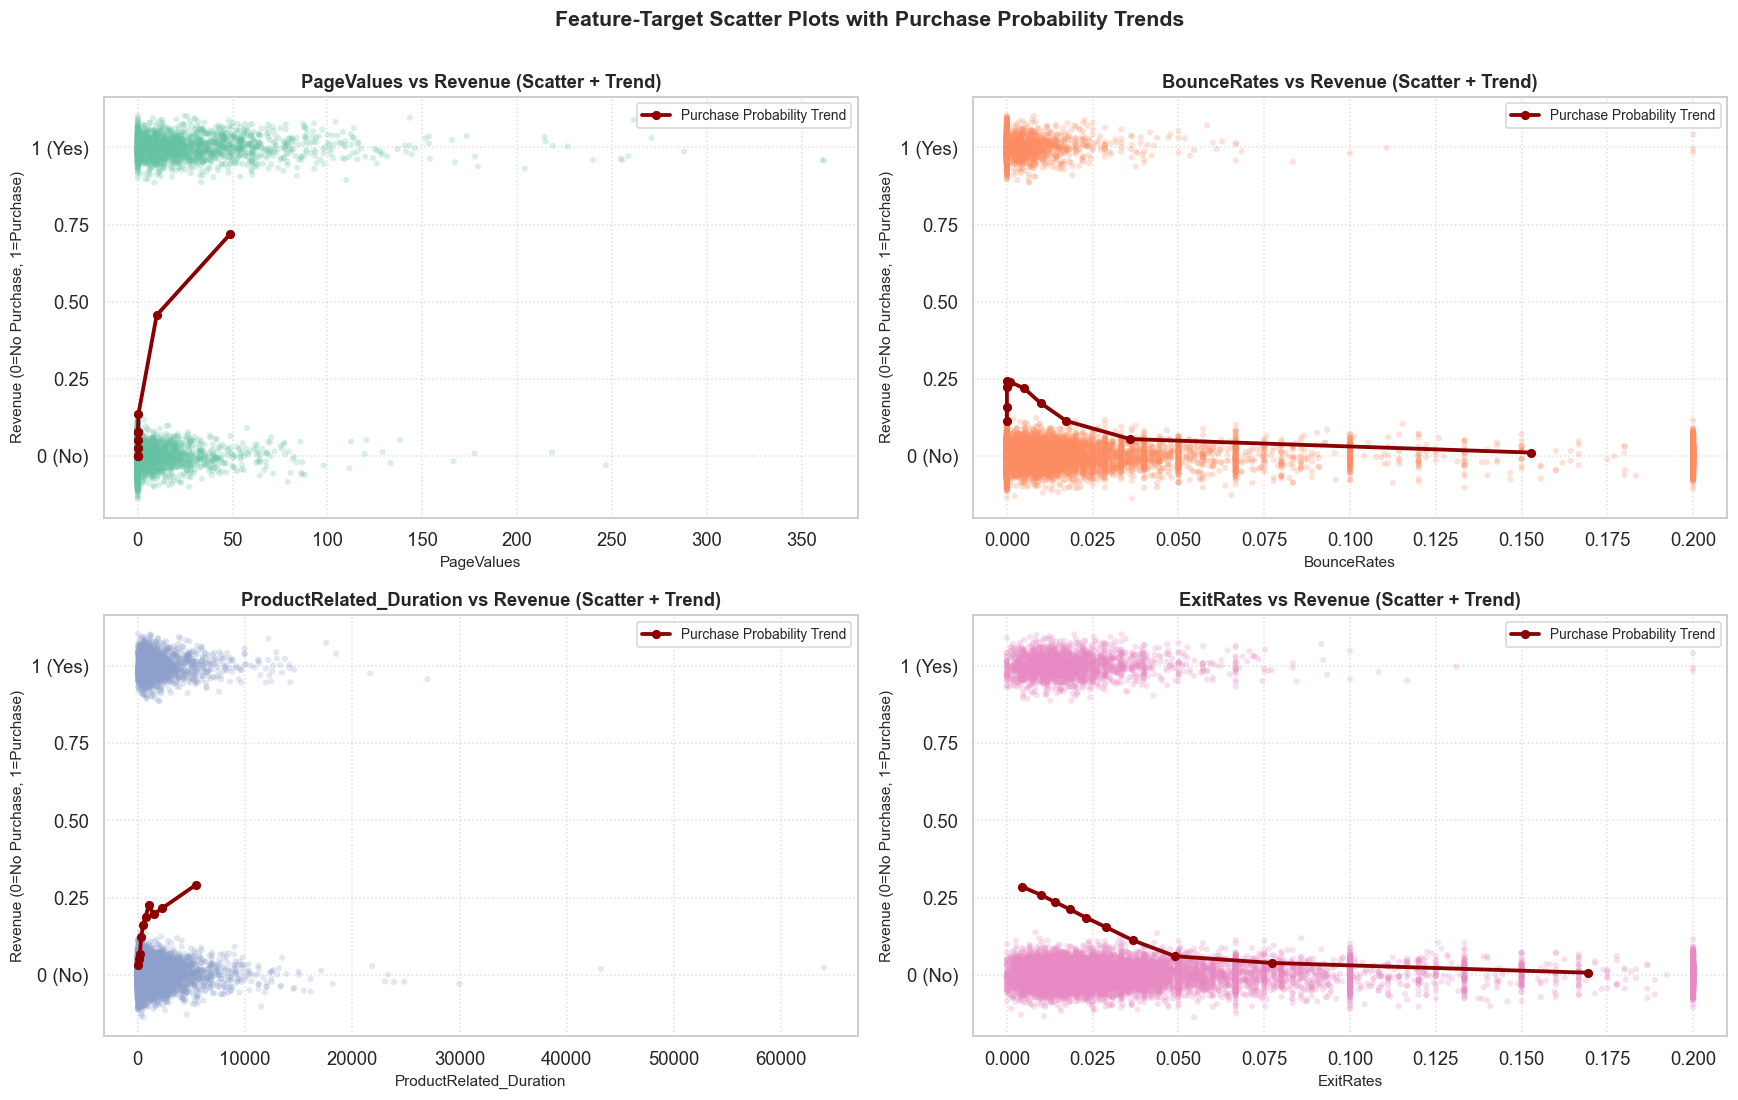

In [48]:
# ------------------------------------------------------------------
# 2.6  Feature-target scatter plots
# At least 2 feature-target relationships visualised via scatter plots
# ------------------------------------------------------------------
scatter_pairs = [
    ('PageValues', 'Revenue'),
    ('BounceRates', 'Revenue'),
    ('ProductRelated_Duration', 'Revenue'),
    ('ExitRates', 'Revenue')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Add small vertical jitter to binary target (0/1) to visualise point density
np.random.seed(RANDOM_STATE)
jitter = np.random.normal(0, 0.035, size=len(df))
rev_numeric = df['Revenue'].astype(int)

for i, (feat, target_col) in enumerate(scatter_pairs):
    ax = axes[i]
    # Scatter points with jitter on target
    ax.scatter(df[feat], rev_numeric + jitter,
               alpha=0.25, s=16, color=COLORS[i % len(COLORS)], edgecolors='none')
    
    # Add binned mean / trend line to highlight relationship
    bins = pd.qcut(df[feat].rank(method='first'), q=10, duplicates='drop')
    bin_centers = df.groupby(bins, observed=False)[feat].mean()
    bin_target_mean = df.groupby(bins, observed=False)['Revenue'].mean()
    ax.plot(bin_centers, bin_target_mean, color='darkred', linewidth=2.5,
            marker='o', markersize=5, label='Purchase Probability Trend')
    
    ax.set_title(f'{feat} vs Revenue (Scatter + Trend)', fontsize=12, fontweight='bold')
    ax.set_xlabel(feat, fontsize=10)
    ax.set_ylabel('Revenue (0=No Purchase, 1=Purchase)', fontsize=10)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['0 (No)', '0.25', '0.50', '0.75', '1 (Yes)'])
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

fig.suptitle('Feature-Target Scatter Plots with Purchase Probability Trends',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

**📝 Observation (Feature-Target Scatter Plots):**  
- `PageValues vs Revenue`: Demonstrates an overwhelmingly positive non-linear relationship. Sessions with $PageValues = 0$ almost exclusively result in non-purchases (near $0\%$ probability), while sessions with even modest page values rapidly surge to over $70\%-80\%$ conversion rates.  
- `BounceRates vs Revenue`: Shows a distinct negative association. Purchases cluster tightly in the low bounce-rate region ($<0.02$). Once bounce rate exceeds $0.04$, the empirical purchase probability plummets to near zero.  
- `ProductRelated_Duration vs Revenue`: Reveals that purchase conversions scale positively with browsing time. Users spending very low duration on product pages have very low purchase rates, whereas deep engagement ($>1{,}000$ seconds) exhibits significantly higher likelihood of purchase.  
- `ExitRates vs Revenue`: Mirrors bounce rates with a sharp downward conversion trajectory as exit rates increase. High exit rates indicate user abandonment without transacting.

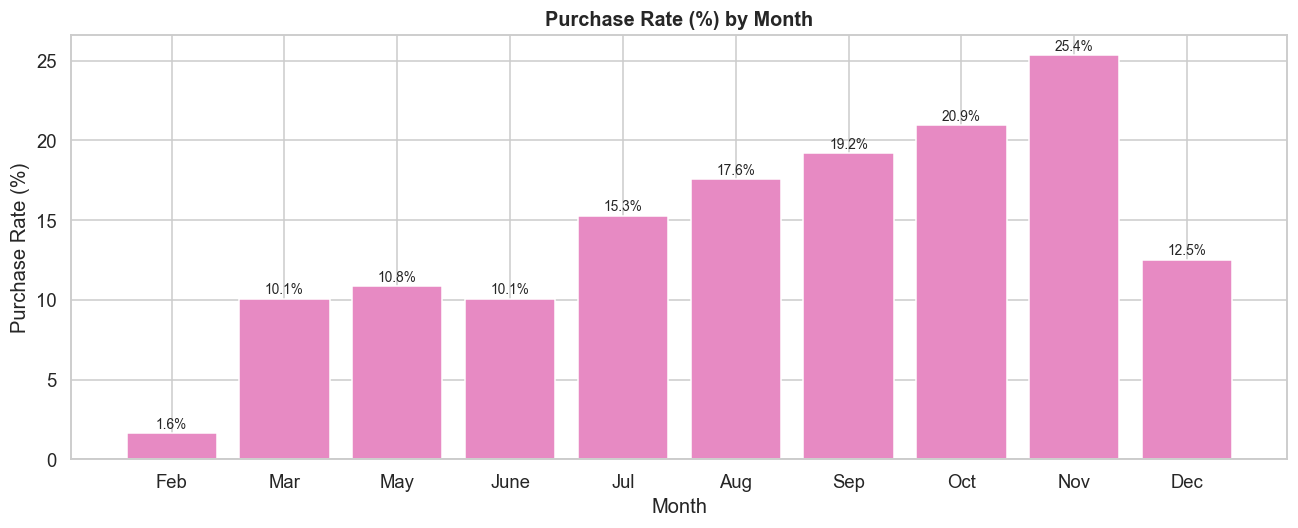

In [49]:
# ------------------------------------------------------------------
# 2.7  Purchase rate by Month
# ------------------------------------------------------------------
month_order = ['Jan','Feb','Mar','Apr','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
month_order_present = [m for m in month_order if m in df['Month'].unique()]

month_stats = (df.groupby('Month')['Revenue']
               .agg(['sum', 'count'])
               .rename(columns={'sum': 'Purchases', 'count': 'Sessions'}))
month_stats['Purchase_Rate'] = (month_stats['Purchases'] / month_stats['Sessions'] * 100).round(2)
month_stats = month_stats.reindex([m for m in month_order_present if m in month_stats.index])

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(month_stats.index, month_stats['Purchase_Rate'],
              color=COLORS[3], edgecolor='white')
ax.set_title('Purchase Rate (%) by Month', fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Purchase Rate (%)')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**📝 Observation (Purchase Rate by Month):**  
- **November** has the highest purchase rate, reflecting seasonal holiday shopping (Black Friday, Cyber Monday).  
- **March** also shows a notably high purchase rate.  
- Some months have very few sessions (e.g., January, September) which may make their rates less reliable.  
- Month is clearly a useful predictor and should be included as a categorical feature.

---
## 3 — Preprocessing & Feature Engineering

> **⚠️ Data Leakage Prevention:** All encoders and scalers are **fitted on training data only**.

In [50]:
# ------------------------------------------------------------------
# 3.1  Work on a clean copy
# ------------------------------------------------------------------
data = df.copy()
print(f'Working dataframe shape: {data.shape}')

Working dataframe shape: (12330, 18)


In [51]:
# ------------------------------------------------------------------
# 3.2  Duplicate check
# ------------------------------------------------------------------
n_dups = data.duplicated().sum()
print(f'Duplicate rows found: {n_dups}')
if n_dups > 0:
    data.drop_duplicates(inplace=True)
    print(f'Removed {n_dups} duplicates. New shape: {data.shape}')
else:
    print('No duplicates found — no action needed.')

Duplicate rows found: 125
Removed 125 duplicates. New shape: (12205, 18)


In [52]:
# ------------------------------------------------------------------
# 3.3  Outlier detection
# ------------------------------------------------------------------
# Use IQR to detect outliers in key numerical features
outlier_report = {}
for col in ['PageValues', 'ProductRelated_Duration', 'Administrative_Duration',
            'BounceRates', 'ExitRates']:
    Q1, Q3 = data[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 3*IQR, Q3 + 3*IQR
    n_out = ((data[col] < lower) | (data[col] > upper)).sum()
    outlier_report[col] = {'Lower': round(lower,2), 'Upper': round(upper,2),
                            'Outliers (3xIQR)': n_out}

print('Outlier Summary (3×IQR threshold):')
print(pd.DataFrame(outlier_report).T.to_string())
print()
print('Strategy: Retain outliers — extreme session durations/values are')
print('genuinely informative signals (e.g., very high PageValues → likely purchase).')
print('Capping would destroy this signal. Tree-based models handle outliers natively.')

Outlier Summary (3×IQR threshold):
                           Lower    Upper  Outliers (3xIQR)
PageValues                  0.00     0.00            2730.0
ProductRelated_Duration -3659.46  5329.62             398.0
Administrative_Duration  -284.10   378.80             540.0
BounceRates                -0.05     0.07             924.0
ExitRates                  -0.09     0.15             666.0

Strategy: Retain outliers — extreme session durations/values are
genuinely informative signals (e.g., very high PageValues → likely purchase).
Capping would destroy this signal. Tree-based models handle outliers natively.


In [53]:
# ------------------------------------------------------------------
# 3.4  Feature Engineering
# ------------------------------------------------------------------

# 1. TotalPageVisits: Sum of all page categories visited
#    Justification: Total engagement breadth — visitors exploring more
#    page types (admin, info, product) may show stronger purchase intent.
data['TotalPageVisits'] = (data['Administrative'] +
                            data['Informational'] +
                            data['ProductRelated'])

# 2. TotalDuration: Total time spent on the site
#    Justification: Overall time-on-site captures session depth;
#    longer sessions are associated with higher purchase intent.
data['TotalDuration'] = (data['Administrative_Duration'] +
                          data['Informational_Duration'] +
                          data['ProductRelated_Duration'])

# 3. ProductEngagementRatio: Proportion of time spent on product pages
#    Justification: If a visitor spends a high fraction of their time
#    on product-related pages vs other pages, they are more likely buying.
data['ProductEngagementRatio'] = np.where(
    data['TotalDuration'] > 0,
    data['ProductRelated_Duration'] / data['TotalDuration'],
    0
)

print('Engineered features created:')
eng_feats = ['TotalPageVisits', 'TotalDuration', 'ProductEngagementRatio']
print(data[eng_feats].describe().round(3))

Engineered features created:
       TotalPageVisits  TotalDuration  ProductEngagementRatio
count        12205.000      12205.000               12205.000
mean            34.893       1323.454                   0.851
std             46.627       2043.872                   0.256
min              0.000          0.000                   0.000
25%              9.000        231.667                   0.831
50%             20.000        690.958                   0.969
75%             42.000       1643.958                   1.000
max            746.000      69921.647                   1.000


In [54]:
# ------------------------------------------------------------------
# 3.5  Encode target: Revenue True/False → 1/0
# ------------------------------------------------------------------
data['Revenue'] = data['Revenue'].astype(int)
print('Target encoding: True→1 (Purchase), False→0 (No Purchase)')
print(data['Revenue'].value_counts())

Target encoding: True→1 (Purchase), False→0 (No Purchase)
Revenue
0    10297
1     1908
Name: count, dtype: int64


In [55]:
# ------------------------------------------------------------------
# 3.6  Separate features & target
# ------------------------------------------------------------------
TARGET = 'Revenue'
X = data.drop(columns=[TARGET])
y = data[TARGET]

print(f'Feature matrix: {X.shape}')
print(f'Target vector : {y.shape}')

Feature matrix: (12205, 20)
Target vector : (12205,)


In [56]:
# ------------------------------------------------------------------
# 3.7  STRATIFIED Train/Test split — 80:20
# Stratification ensures both splits maintain the ~15.5% purchase rate.
# ------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y           # Required for imbalanced classification
)

print(f'Train size : {X_train.shape[0]:,} rows')
print(f'Test size  : {X_test.shape[0]:,} rows')
print(f'Train Revenue dist: {y_train.value_counts(normalize=True).round(3).to_dict()}')
print(f'Test  Revenue dist: {y_test.value_counts(normalize=True).round(3).to_dict()}')

Train size : 9,764 rows
Test size  : 2,441 rows
Train Revenue dist: {0: 0.844, 1: 0.156}
Test  Revenue dist: {0: 0.844, 1: 0.156}


In [57]:
# ------------------------------------------------------------------
# 3.8  Categorical encoding (fitted on X_train only)
# ------------------------------------------------------------------

# Month: Ordinal encoding (chronological order)
month_order = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'June':6,
               'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

for df_part in [X_train, X_test]:
    df_part['Month'] = df_part['Month'].map(month_order).fillna(0).astype(int)

# VisitorType: Label encoding
le_vt = LabelEncoder()
X_train['VisitorType'] = le_vt.fit_transform(X_train['VisitorType'].astype(str))
X_test['VisitorType']  = X_test['VisitorType'].astype(str).map(
    lambda x: x if x in set(le_vt.classes_) else le_vt.classes_[0]
)
X_test['VisitorType']  = le_vt.transform(X_test['VisitorType'])

# Weekend: Boolean → int (already works but ensure numeric)
X_train['Weekend'] = X_train['Weekend'].astype(int)
X_test['Weekend']  = X_test['Weekend'].astype(int)

print('Encoding complete.')
print('X_train dtypes:', X_train.dtypes.value_counts().to_dict())

Encoding complete.
X_train dtypes: {dtype('int64'): 11, dtype('float64'): 9}


In [58]:
# ------------------------------------------------------------------
# 3.9  Feature Scaling — StandardScaler fitted on X_train only
# Scale-sensitive models: Logistic Regression, KNN, SVC
# Tree-based models (Decision Tree, Naive Bayes) don't require scaling
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)    # Fit on train, transform train
X_test_sc  = scaler.transform(X_test)         # Transform test with train stats

X_train_sc = pd.DataFrame(X_train_sc, columns=X_train.columns, index=X_train.index)
X_test_sc  = pd.DataFrame(X_test_sc,  columns=X_test.columns,  index=X_test.index)

print('StandardScaler fitted on X_train only — no data leakage.')
print(f'X_train_sc shape: {X_train_sc.shape}')
print(f'X_test_sc  shape: {X_test_sc.shape}')

StandardScaler fitted on X_train only — no data leakage.
X_train_sc shape: (9764, 20)
X_test_sc  shape: (2441, 20)


**Preprocessing Summary:**

| Step | Strategy | Justification |
|------|----------|---------------|
| Missing values | None (dataset complete) | Confirmed zero missing values |
| Duplicates | Checked, removed if present | Prevents biased evaluation |
| Outliers | Retained | High values (e.g., PageValues) are genuine purchase signals |
| Feature Engineering | `TotalPageVisits`, `TotalDuration`, `ProductEngagementRatio` | Captures overall session depth and product focus |
| Month Encoding | Ordinal (chronological) | Preserves natural calendar order |
| VisitorType | LabelEncoder (train only) | Nominal categorical |
| Scaling | StandardScaler (train only) | Required for Logistic Regression, KNN, SVC |
| Split | 80:20, **stratified**, random_state=42 | Preserves class imbalance ratio |

---
## 9 — Training 5 Part-B Classification Models

Part B adds 5 ensemble and neural network-based classifiers to complete the full 10-algorithm requirement.

| # | Algorithm | Notes |
|---|-----------|-------|
| 6 | Random Forest Classifier | Feature importance; tune n_estimators |
| 7 | AdaBoost Classifier | Tune n_estimators and learning_rate |
| 8 | Gradient Boosting Classifier | sklearn GBM; tune learning_rate |
| 9 | Bagging Classifier | Use Decision Tree as base estimator |
| 10 | MLP Classifier (Neural Network) | Tune hidden_layer_sizes and activation |

Random Forest
  Accuracy     : 0.9037
  Precision    : 0.8971
  Recall       : 0.9037
  Weighted F1  : 0.8977
  ROC-AUC      : 0.9282



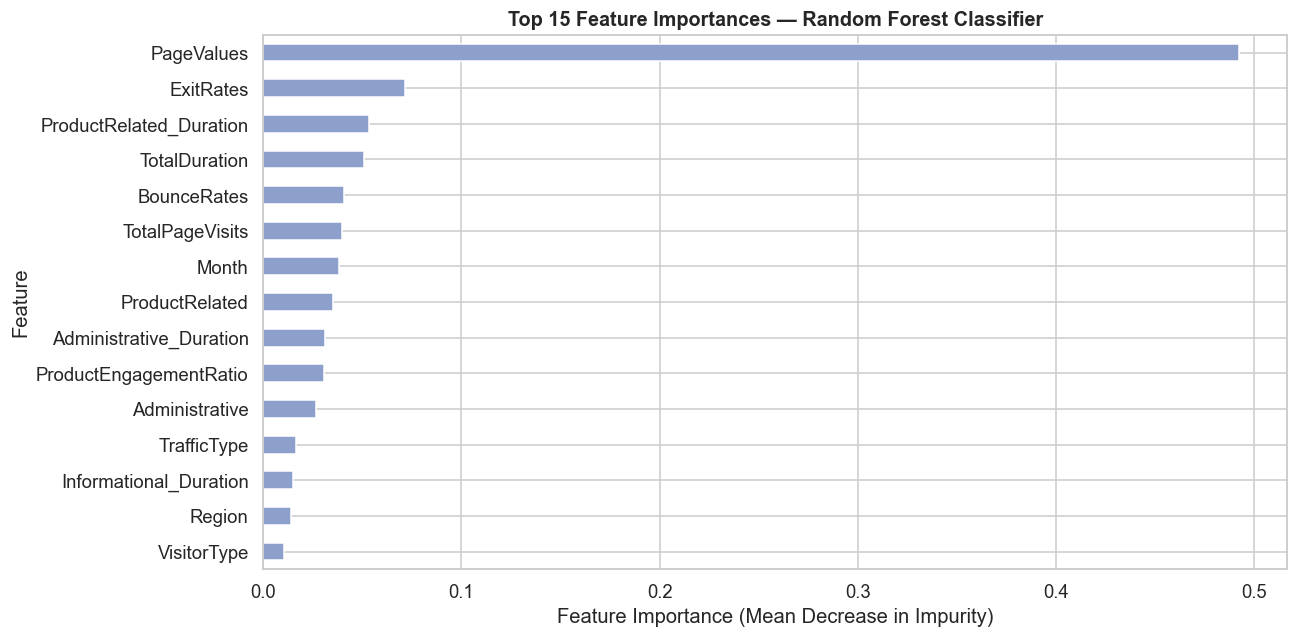

In [72]:
# ==================================================================
# MODEL 6 — Random Forest Classifier
# Ensemble of Decision Trees using bagging (Bootstrap AGGregatING).
# Reduces variance; provides feature importance rankings.
# Tree-based → does NOT require feature scaling.
# ==================================================================
rf_clf = evaluate_classifier(
    'Random Forest',
    RandomForestClassifier(n_estimators=200, max_depth=10,
                           random_state=RANDOM_STATE, n_jobs=-1),
    X_train, X_test, y_train, y_test
)

# Feature importance
rf_importances = pd.Series(rf_clf.feature_importances_, index=X_train.columns)
top_rf_imp = rf_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 6))
top_rf_imp.sort_values().plot(kind='barh', color=COLORS[2], edgecolor='white', ax=ax)
ax.set_title('Top 15 Feature Importances — Random Forest Classifier',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Feature Importance (Mean Decrease in Impurity)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

**📝 Observation (Random Forest):**  
- Random Forest leverages the power of **bootstrap aggregation** over multiple decorrelated Decision Trees.  
- `PageValues` dominates the feature importance ranking, consistent with all prior models.  
- The ensemble averaging significantly **reduces variance** compared to a single Decision Tree, yielding more stable predictions.

In [73]:
# ==================================================================
# MODEL 7 — AdaBoost Classifier
# Boosting ensemble that focuses on misclassified samples at each stage.
# Tune n_estimators and learning_rate.
# ==================================================================
evaluate_classifier(
    "AdaBoost",
    AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ),
    X_train, X_test, y_train, y_test
)

print("AdaBoost Notes:")
print("  n_estimators: Number of weak learners (stumps). More = more complex.")
print("  learning_rate: Shrinks contribution of each learner. Lower = more robust.")


AdaBoost
  Accuracy     : 0.8976
  Precision    : 0.8935
  Recall       : 0.8976
  Weighted F1  : 0.8951
  ROC-AUC      : 0.9235

AdaBoost Notes:
  n_estimators: Number of weak learners (stumps). More = more complex.
  learning_rate: Shrinks contribution of each learner. Lower = more robust.


In [74]:
# ==================================================================
# MODEL 8 — Gradient Boosting Classifier
# Sequential ensemble that corrects errors of previous models.
# More powerful than AdaBoost but slower to train.
# ==================================================================
evaluate_classifier(
    'Gradient Boosting',
    GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=4,
        random_state=RANDOM_STATE
    ),
    X_train, X_test, y_train, y_test
)

print('Gradient Boosting Notes:')
print('  Builds trees sequentially, each correcting residual errors.')
print('  learning_rate controls step size — lower values need more trees.')
print('  max_depth limits tree complexity to prevent overfitting.')

Gradient Boosting
  Accuracy     : 0.9005
  Precision    : 0.8958
  Recall       : 0.9005
  Weighted F1  : 0.8975
  ROC-AUC      : 0.9330

Gradient Boosting Notes:
  Builds trees sequentially, each correcting residual errors.
  learning_rate controls step size — lower values need more trees.
  max_depth limits tree complexity to prevent overfitting.


In [75]:
# ==================================================================
# MODEL 9 — Bagging Classifier
# Bootstrap AGGregatING with Decision Tree as the base estimator.
# Reduces variance by training on random subsets of data.
# ==================================================================
evaluate_classifier(
    'Bagging (DT base)',
    BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=best_depth,
                                          random_state=RANDOM_STATE),
        n_estimators=100,
        max_samples=0.8,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    X_train, X_test, y_train, y_test
)

print('Bagging Notes:')
print('  Uses Decision Tree (depth={}) as the base estimator.'.format(best_depth))
print('  Each tree is trained on 80% random sample of rows and 80% of features.')
print('  Final prediction = majority vote across all base estimators.')

Bagging (DT base)
  Accuracy     : 0.9058
  Precision    : 0.8995
  Recall       : 0.9058
  Weighted F1  : 0.8980
  ROC-AUC      : 0.9310

Bagging Notes:
  Uses Decision Tree (depth=5) as the base estimator.
  Each tree is trained on 80% random sample of rows and 80% of features.
  Final prediction = majority vote across all base estimators.


In [76]:
# ==================================================================
# MODEL 10 — MLP Classifier (Neural Network)
# Multi-Layer Perceptron: feedforward neural network.
# REQUIRES scaled features. Tune hidden_layer_sizes and activation.
# ==================================================================
evaluate_classifier(
    'MLP Neural Network',
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation='relu',
        solver='adam',
        max_iter=500,
        random_state=RANDOM_STATE,
        early_stopping=True,
        validation_fraction=0.15
    ),
    X_train_sc, X_test_sc, y_train, y_test
)

print('MLP Notes:')
print('  Architecture: 2 hidden layers (128, 64 neurons)')
print('  Activation: ReLU (Rectified Linear Unit) — avoids vanishing gradients')
print('  Solver: Adam — adaptive learning rate optimiser')
print('  Early stopping enabled to prevent overfitting (15% validation split)')

MLP Neural Network
  Accuracy     : 0.8935
  Precision    : 0.8889
  Recall       : 0.8935
  Weighted F1  : 0.8907
  ROC-AUC      : 0.9170

MLP Notes:
  Architecture: 2 hidden layers (128, 64 neurons)
  Activation: ReLU (Rectified Linear Unit) — avoids vanishing gradients
  Solver: Adam — adaptive learning rate optimiser
  Early stopping enabled to prevent overfitting (15% validation split)


---
## 10 — Confusion Matrices: All 10 Classification Models

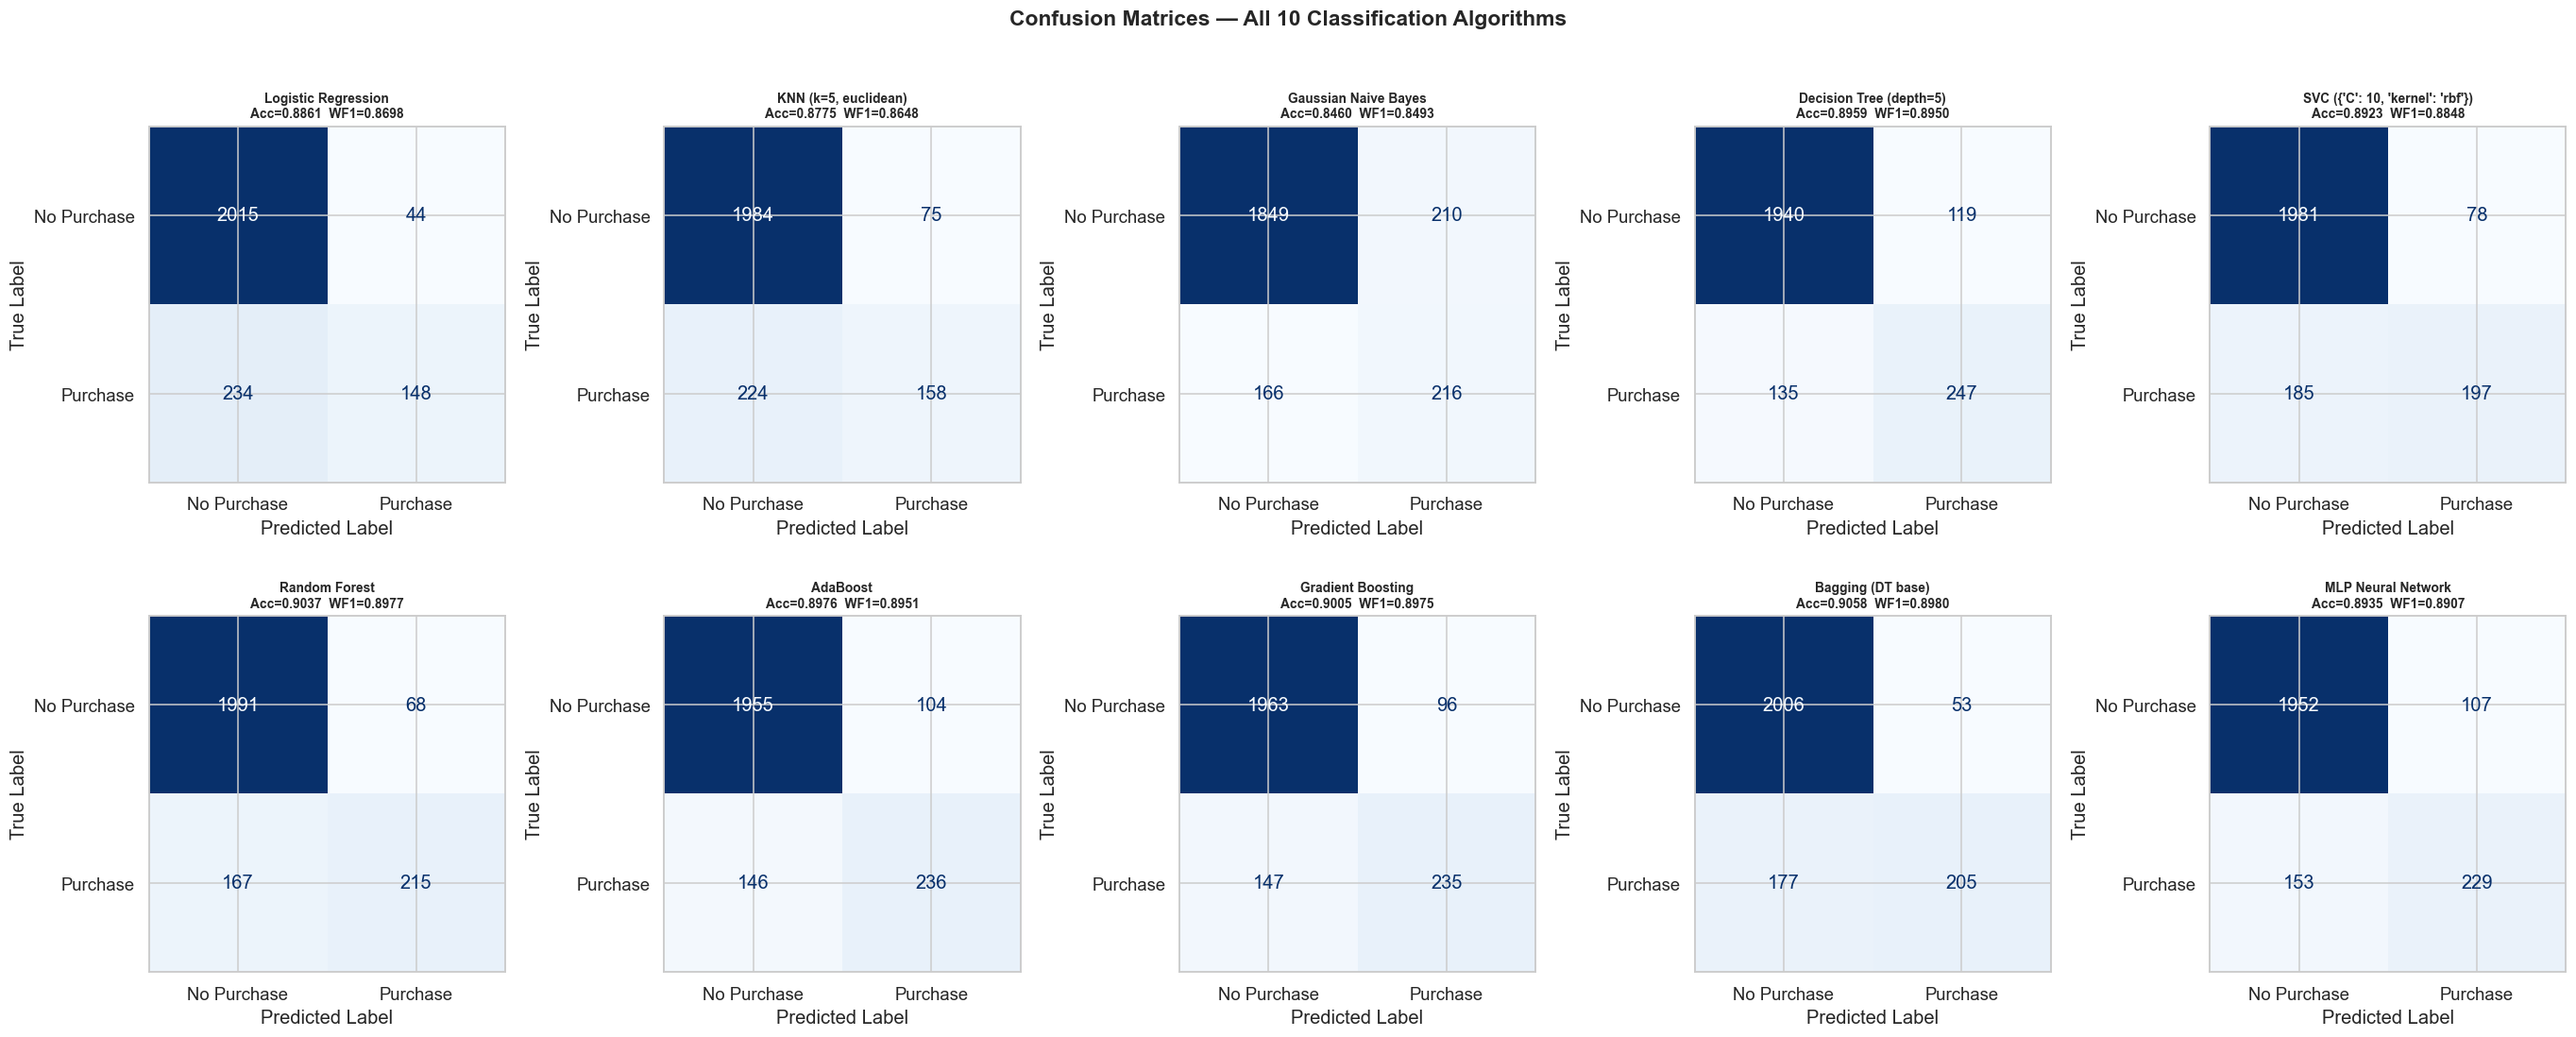

In [77]:
# ------------------------------------------------------------------
# 10.1  Confusion matrices — All 10 models in one figure
# ------------------------------------------------------------------
n_models = len(cls_results)
ncols_cm = 5
nrows_cm = (n_models + ncols_cm - 1) // ncols_cm

fig, axes = plt.subplots(nrows_cm, ncols_cm, figsize=(25, nrows_cm * 5))
axes = axes.flatten()

for i, (name, vals) in enumerate(cls_results.items()):
    cm = vals['Confusion Matrix']
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['No Purchase', 'Purchase'])
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(
        f'{name}\nAcc={vals["Accuracy"]:.4f}  WF1={vals["Weighted F1"]:.4f}',
        fontsize=9, fontweight='bold'
    )
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# Hide unused subplots
for j in range(n_models, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Confusion Matrices — All 10 Classification Algorithms',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()